# Emotion Classification with Attention

Multi-class emotion classifier (6 core emotions: **joy, sadness, anger, fear, surprise, disgust**) trained on the **GoEmotions** dataset, with the training split topped up with **ISEAR** examples for the rarest classes (`disgust`, `fear`).

We build and compare four architectures under identical data splits and evaluation:

1. LSTM
2. GRU
3. BiLSTM + Additive Attention
4. Fine-tuned Transformer — RoBERTa by default (HuggingFace `Trainer` API)

**Notebook outline**

1. Setup and Configuration
2. Data Loading and Exploration
3. Label Mapping to 6 Emotions (+ augmenting `disgust`/`fear` with ISEAR)
4. Text Cleaning, Tokenization and Padding
5. Pre-trained Embeddings (GloVe)
6. Model Architectures
7. Training Utilities
8. Training the Custom Sequence Models
9. Evaluation of the Custom Models
10. Attention Visualization
11. Fine-tuning a Transformer with HuggingFace
12. Final Comparison
13. Saving Artifacts
14. Conclusions and Next Steps

## 1. Setup and Configuration

This stage installs dependencies, defines a single `Config` object that holds every hyperparameter, and fixes all random seeds for reproducibility.

### 1.1 Install dependencies

Skip this cell if the packages are already installed (Colab already has most of them).

In [ ]:
!pip install -q datasets transformers accelerate gensim scikit-learn seaborn sentencepiece

### 1.2 Imports

In [ ]:
import copy
import json
import logging
import random
import re
import time
from collections import Counter
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import Dataset, DatasetDict, load_dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, TensorDataset

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("emotion-clf")
sns.set_theme(style="whitegrid", context="notebook")

### 1.3 Configuration and reproducibility

In [ ]:
@dataclass
class Config:
    # Reproducibility
    seed: int = 42

    # Data
    dataset_name: str = "google-research-datasets/go_emotions"
    dataset_config: str = "simplified"
    max_len_percentile: int = 95      # sequence length = this percentile of train lengths
    max_len_cap: int = 64
    min_freq: int = 2                 # minimum token frequency to enter the vocabulary
    sampling_alpha: float = 0.5       # class-balancing temperature: 1.0 = full inverse-frequency, 0.5 = sqrt-dampened (gentler)

    # Embeddings
    glove_name: str = "glove-twitter-100"   # gensim-downloader name (informal text suits Reddit comments)
    freeze_embeddings: bool = False

    # Recurrent models
    hidden_dim: int = 128
    num_layers: int = 1
    dropout: float = 0.4
    attention_dim: int = 64

    # Training (recurrent models)
    batch_size: int = 128
    lr: float = 1e-3
    weight_decay: float = 1e-4
    epochs: int = 15
    patience: int = 3                 # early stopping on validation macro F1
    grad_clip: float = 1.0

    # Transformer
    transformer_name: str = "roberta-large"  # 355M parameters - largest capacity option, needs a lower LR and smaller per-step batch
    transformer_epochs: int = 6              # EarlyStoppingCallback stops earlier if validation macro F1 stops improving
    transformer_patience: int = 2
    transformer_lr: float = 1e-5             # large models fine-tune best with a smaller LR than base-sized ones
    transformer_batch_size: int = 8          # kept small so a free Colab T4 (~15 GB) can hold the model + activations
    transformer_grad_accum: int = 4          # effective batch size = 8 * 4 = 32, without needing more GPU memory
    transformer_max_len: int = 64

    # Output
    output_dir: str = "artifacts"


cfg = Config()


def set_seed(seed: int) -> None:
    """Seed every source of randomness we rely on."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(cfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path(cfg.output_dir)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
logger.info("Using device: %s", device)

## 2. Data Loading and Exploration

We load the **simplified** configuration of GoEmotions (pre-defined train/validation/test splits, 28 labels: 27 emotions + neutral, multi-label).

### 2.1 Load the dataset

In [ ]:
raw = load_dataset(cfg.dataset_name, cfg.dataset_config)
GO_LABELS: List[str] = raw["train"].features["labels"].feature.names

print(raw)
print(f"\nNumber of original labels: {len(GO_LABELS)}")
print(GO_LABELS)

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})

Number of original labels: 28
['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


### 2.2 Inspect raw samples

In [ ]:
sample_df = raw["train"].to_pandas().sample(8, random_state=cfg.seed)
sample_df["label_names"] = sample_df["labels"].apply(lambda ids: [GO_LABELS[i] for i in ids])
sample_df[["text", "label_names"]]

,text,label_names
25759,The only way this works is if [NAME] is doing ...,[neutral]
22531,Access should be hindered it's getting destroyed.,[annoyance]
18418,Totally fair. All I was trying to remind every...,[approval]
31117,"I'm poly and jn the Raleigh area too, moved he...",[surprise]
5733,Naw man Asain men have an easier time. Most of...,[amusement]
17987,That scene traumatized me the first time I wat...,[fear]
5343,"No, some of us thought it was gross back then ...",[neutral]
7133,Sounds like they’re not responsible and should...,"[disapproval, realization]"


### 2.3 Original label distribution and text length

GoEmotions is **multi-label** and heavily skewed towards *neutral*, so we inspect both the label frequencies and the number of labels per example.

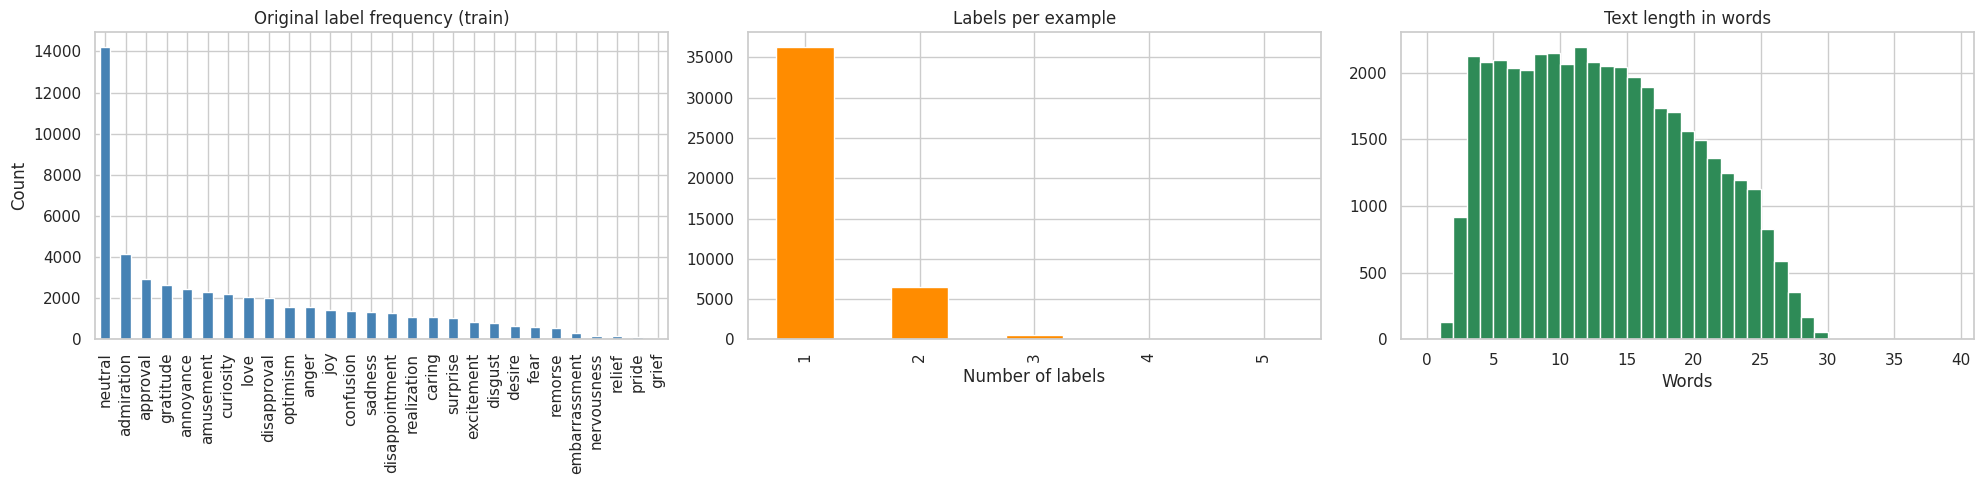

Train examples: 43,410
Share with more than one label: 16.4%
Mean / median / 95th percentile words: 12.8 / 12 / 24


In [ ]:
train_raw_df = raw["train"].to_pandas()

label_counts = Counter(GO_LABELS[i] for ids in train_raw_df["labels"] for i in ids)
label_counts_df = pd.Series(label_counts).sort_values(ascending=False)

labels_per_example = train_raw_df["labels"].apply(len)
word_lengths = train_raw_df["text"].str.split().apply(len)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
label_counts_df.plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Original label frequency (train)")
axes[0].set_ylabel("Count")

labels_per_example.value_counts().sort_index().plot.bar(ax=axes[1], color="darkorange")
axes[1].set_title("Labels per example")
axes[1].set_xlabel("Number of labels")

axes[2].hist(word_lengths, bins=range(0, 40), color="seagreen")
axes[2].set_title("Text length in words")
axes[2].set_xlabel("Words")
plt.tight_layout()
plt.show()

print(f"Train examples: {len(train_raw_df):,}")
print(f"Share with more than one label: {(labels_per_example > 1).mean():.1%}")
print(f"Mean / median / 95th percentile words: {word_lengths.mean():.1f} / {word_lengths.median():.0f} / {word_lengths.quantile(0.95):.0f}")

## 3. Label Mapping to 6 Emotions

The project targets **6 Ekman emotions**. We map each of the 27 GoEmotions emotions to one of them, using the Ekman grouping published with the dataset.

### 3.1 Mapping definition

`neutral` has no Ekman counterpart and is excluded.

In [ ]:
TARGET_EMOTIONS = ["joy", "sadness", "anger", "fear", "surprise", "disgust"]
EMOTION2ID = {name: idx for idx, name in enumerate(TARGET_EMOTIONS)}
ID2EMOTION = {idx: name for name, idx in EMOTION2ID.items()}
NUM_CLASSES = len(TARGET_EMOTIONS)

EKMAN_MAPPING: Dict[str, List[str]] = {
    "joy": ["joy", "amusement", "approval", "excitement", "gratitude", "love",
            "optimism", "relief", "admiration", "desire", "caring", "pride"],
    "sadness": ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "anger": ["anger", "annoyance", "disapproval"],
    "fear": ["fear", "nervousness"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
    "disgust": ["disgust"],
}
GO_TO_EKMAN = {go: ekman for ekman, members in EKMAN_MAPPING.items() for go in members}

# Safety check: every non-neutral GoEmotions label must be mapped exactly once.
assert set(GO_LABELS) - {"neutral"} == set(GO_TO_EKMAN), "Mapping does not cover all GoEmotions labels"
print({k: len(v) for k, v in EKMAN_MAPPING.items()})

{'joy': 12, 'sadness': 5, 'anger': 3, 'fear': 2, 'surprise': 4, 'disgust': 1}


### 3.2 Apply the mapping

Examples with no target emotion (neutral-only) get dropped everywhere. Examples with two or more target emotions are treated differently per split though: in **train** we resolve them towards the rarer emotion instead of dropping them (more `disgust`/`fear` examples to learn from), but in **validation/test** we still drop them — resolving ambiguous labels in the eval sets would mean part of the "ground truth" is just our own guess, and that quietly messes with the metrics (learned this the hard way in an earlier run).

In [ ]:
# rarest-first order, used below to resolve train examples that have more than one target emotion
go_freq = Counter(GO_LABELS[i] for ids in raw["train"]["labels"] for i in ids)
ekman_freq = {emotion: sum(go_freq[go] for go in members) for emotion, members in EKMAN_MAPPING.items()}
PRIORITY_ORDER = sorted(ekman_freq, key=ekman_freq.get)
print("priority order (rarest first):", PRIORITY_ORDER)


def to_target_label(label_ids, resolve_ambiguous: bool) -> int:
    """Return the target class id, -1 if no target emotion (neutral-only), -2 if ambiguous and not resolved."""
    emotions = {GO_TO_EKMAN[GO_LABELS[i]] for i in label_ids if GO_LABELS[i] in GO_TO_EKMAN}
    if not emotions:
        return -1
    if len(emotions) == 1:
        return EMOTION2ID[next(iter(emotions))]
    if resolve_ambiguous:                    # train only: push towards the rarer class instead of dropping
        for emotion in PRIORITY_ORDER:
            if emotion in emotions:
                return EMOTION2ID[emotion]
    return -2


def build_frame(split: str, resolve_ambiguous: bool) -> pd.DataFrame:
    df = raw[split].to_pandas()[["text", "labels"]]
    df["label"] = df["labels"].apply(lambda ids: to_target_label(ids, resolve_ambiguous))
    total = len(df)
    n_neutral = int((df["label"] == -1).sum())
    n_ambiguous_dropped = int((df["label"] == -2).sum())
    df = df[df["label"] >= 0].drop(columns="labels").reset_index(drop=True)
    logger.info("%-10s total=%6d | kept=%6d | neutral-only dropped=%6d | ambiguous %s=%5d",
                split, total, len(df), n_neutral,
                "resolved by priority" if resolve_ambiguous else "dropped", n_ambiguous_dropped if not resolve_ambiguous else 0)
    return df


frames = {
    "train": build_frame("train", resolve_ambiguous=True),
    "validation": build_frame("validation", resolve_ambiguous=False),
    "test": build_frame("test", resolve_ambiguous=False),
}

priority order (rarest first): ['fear', 'disgust', 'sadness', 'surprise', 'anger', 'joy']


### 3.3 Class distribution after mapping

The classes are imbalanced — `disgust` and `fear` barely have a few hundred examples versus thousands for `joy`. This is the main ceiling on model quality (bigger models did not meaningfully move macro F1 in earlier experiments), so Section 3.4 brings in real extra examples for the weakest classes rather than just reweighting the loss.

,train,validation,test
label,,,
joy,15809,2017,1937
sadness,3182,278,298
anger,4948,596,609
fear,726,77,85
surprise,5141,497,533
disgust,781,62,77


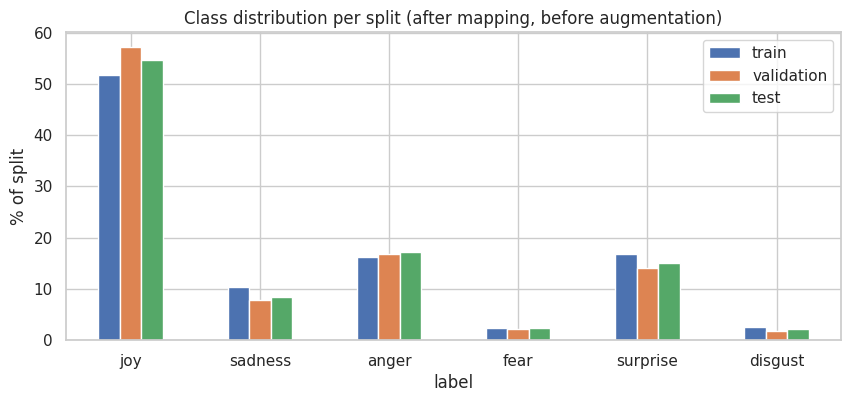

In [ ]:
dist = pd.DataFrame({
    split: frames[split]["label"].map(ID2EMOTION).value_counts().reindex(TARGET_EMOTIONS)
    for split in frames
})
display(dist)

dist_pct = dist.div(dist.sum()).mul(100).round(1)
ax = dist_pct.plot.bar(figsize=(10, 4))
ax.set_ylabel("% of split")
ax.set_title("Class distribution per split (after mapping, before augmentation)")
plt.xticks(rotation=0)
plt.show()

### 3.4 Augmenting the rare classes with ISEAR

`disgust` and `fear` just don't have enough GoEmotions examples to learn from. ISEAR is a separate dataset (~1,080 sentences per emotion, roughly balanced across 7 emotions) that we can pull `disgust`/`fear` sentences from and add to **train only** — val/test stay pure GoEmotions so the metrics are still comparable to earlier runs.

Note: ISEAR sentences are longer, first-person narratives, a different style from GoEmotions' short comments. Worth keeping an eye on in the per-class results below.

### 3.4.1 Download and clean ISEAR

In [ ]:
ISEAR_URL = "https://raw.githubusercontent.com/sinmaniphel/py_isear_dataset/master/isear.csv"
ISEAR_AUGMENT_CLASSES = ["disgust", "fear"]  # the two weakest classes; add more target-emotion names here to extend

isear_raw = pd.read_csv(ISEAR_URL, sep="|", encoding="utf-8", engine="python", on_bad_lines="skip")
isear_raw = isear_raw[["Field1", "SIT"]].rename(columns={"Field1": "label_name", "SIT": "text"})


def clean_isear_text(text: str) -> str:
    """This particular ISEAR mirror has a line-wrap artifact ('\u00e1' inserted at wrap points); strip it."""
    text = str(text).replace("\u00e1", "")
    return re.sub(r"\s+", " ", text).strip()


isear_raw["text"] = isear_raw["text"].apply(clean_isear_text)

# Drop non-answers ("[No response.]", "[Never felt this emotion.]", ...) and anything too short to be useful.
NON_RESPONSE_RE = re.compile(
    r"no response|never felt|never experienced|do not remember|do not know|"
    r"can ?not (?:recall|think)|no description|no answer|not experienced", re.IGNORECASE,
)
is_junk = (
    isear_raw["text"].str.contains(r"[\[\]]", regex=True)
    | isear_raw["text"].str.contains(NON_RESPONSE_RE)
    | (isear_raw["text"].str.len() < 15)
)
isear_clean = isear_raw[~is_junk].reset_index(drop=True)
print(f"ISEAR rows downloaded: {len(isear_raw):,} | kept after cleaning: {len(isear_clean):,}")
isear_clean.head(5)

ISEAR rows downloaded: 7,503 | kept after cleaning: 7,257


,label_name,text
0,joy,"During the period of falling in love, each tim..."
1,fear,When I was involved in a traffic accident.
2,anger,When I was driving home after several days of ...
3,sadness,When I lost the person who meant the most to me.
4,disgust,The time I knocked a deer down - the sight of ...


### 3.4.2 Keep the target classes and merge into the training split

In [ ]:
isear_subset = isear_clean[isear_clean["label_name"].isin(ISEAR_AUGMENT_CLASSES)].copy()
isear_subset["label"] = isear_subset["label_name"].map(EMOTION2ID)
isear_subset = isear_subset[["text", "label"]]

print("ISEAR examples added to train, by class:")
print(isear_subset["label"].map(ID2EMOTION).value_counts())

before_train_counts = frames["train"]["label"].map(ID2EMOTION).value_counts().reindex(TARGET_EMOTIONS)
frames["train"] = pd.concat([frames["train"], isear_subset], ignore_index=True)
print(f"\nTrain size: {int(before_train_counts.sum()):,} -> {len(frames['train']):,} after augmentation")

ISEAR examples added to train, by class:
label
fear       1055
disgust    1023
Name: count, dtype: int64

Train size: 30,587 -> 32,665 after augmentation


### 3.5 Train-set distribution after augmentation

Recomputed on the **training split only**, now that ISEAR examples are mixed in. Class weights (used later for the transformer's weighted loss) are computed here, after augmentation, so they reflect the final training distribution.

,before ISEAR,after ISEAR
label,,
joy,15809,15809
sadness,3182,3182
anger,4948,4948
fear,726,1781
surprise,5141,5141
disgust,781,1804


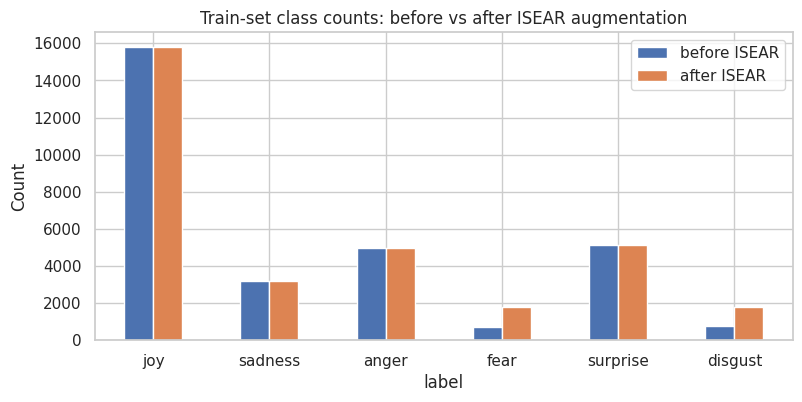

{'joy': 0.59, 'sadness': 1.31, 'anger': 1.05, 'fear': 1.75, 'surprise': 1.03, 'disgust': 1.74}


In [ ]:
after_train_counts = frames["train"]["label"].map(ID2EMOTION).value_counts().reindex(TARGET_EMOTIONS)
train_compare = pd.DataFrame({"before ISEAR": before_train_counts, "after ISEAR": after_train_counts})
display(train_compare)

ax = train_compare.plot.bar(figsize=(9, 4))
ax.set_ylabel("Count")
ax.set_title("Train-set class counts: before vs after ISEAR augmentation")
plt.xticks(rotation=0)
plt.show()

# same alpha damping as the sampler above, applied to the transformer's loss weights
class_weights_balanced = compute_class_weight(
    class_weight="balanced", classes=np.arange(NUM_CLASSES), y=frames["train"]["label"].to_numpy()
)
class_weights_np = class_weights_balanced ** cfg.sampling_alpha
class_weights = torch.tensor(class_weights_np, dtype=torch.float32)
print({ID2EMOTION[i]: round(float(w), 2) for i, w in enumerate(class_weights_np)})

## 4. Text Cleaning, Tokenization and Padding

### 4.1 Cleaning and tokenization

Design choices:

- Lowercase text and normalize curly apostrophes.
- Remove URLs; keep the dataset placeholders `[NAME]` / `[RELIGION]` as plain words.
- Keep `!` and `?` as separate tokens because they carry strong emotional signal.

In [ ]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
PLACEHOLDER_RE = re.compile(r"\[(name|religion)\]")
TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[!?]")


def clean_text(text):
    text = text.lower().replace("\u2019", "'").replace("\u2018", "'")
    text = URL_RE.sub(" ", text)
    text = PLACEHOLDER_RE.sub(lambda m: m.group(1), text)
    return re.sub(r"\s+", " ", text).strip()


def tokenize(text):
    return TOKEN_RE.findall(clean_text(text))


print(tokenize("OMG!!! [NAME] you didn't tell me?? Check https://example.com \u2019 :)"))

for split, df in frames.items():
    df["tokens"] = df["text"].apply(tokenize)

['omg', '!', '!', '!', 'name', 'you', "didn't", 'tell', 'me', '?', '?', 'check']


### 4.2 Vocabulary (built from the training split only)

Building the vocabulary only on the training split prevents information leakage from validation/test data.

In [ ]:
class Vocabulary:
    PAD, UNK = "<pad>", "<unk>"

    def __init__(self, min_freq: int = 2):
        self.min_freq = min_freq
        self.itos: List[str] = [self.PAD, self.UNK]
        self.stoi: Dict[str, int] = {self.PAD: 0, self.UNK: 1}

    def build(self, tokenized_texts: List[List[str]]) -> "Vocabulary":
        counter = Counter(tok for tokens in tokenized_texts for tok in tokens)
        for tok, freq in counter.most_common():
            if freq >= self.min_freq and tok not in self.stoi:
                self.stoi[tok] = len(self.itos)
                self.itos.append(tok)
        return self

    def encode(self, tokens: List[str], max_len: int) -> Tuple[List[int], int]:
        ids = [self.stoi.get(t, 1) for t in tokens[:max_len]]
        length = len(ids)
        ids += [0] * (max_len - length)
        return ids, length

    def __len__(self) -> int:
        return len(self.itos)


vocab = Vocabulary(cfg.min_freq).build(frames["train"]["tokens"].tolist())

train_token_lengths = frames["train"]["tokens"].apply(len)
MAX_LEN = int(min(np.percentile(train_token_lengths, cfg.max_len_percentile), cfg.max_len_cap))

print(f"Vocabulary size: {len(vocab):,}")
print(f"Sequence length (p{cfg.max_len_percentile}): {MAX_LEN}")

Vocabulary size: 11,270
Sequence length (p95): 26


### 4.3 Encode, pad to a fixed length and build DataLoaders

Each split becomes three tensors: padded token ids, true (unpadded) lengths, and labels. True lengths are used later for packing and for attention masking.

The **training** loader uses a `WeightedRandomSampler` so the rare classes are seen more often during training (oversampling `disgust`/`fear`, undersampling `joy`), instead of leaving the imbalance to be corrected only through the loss function. The sampling is **dampened** (`cfg.sampling_alpha = 0.5`, i.e. weight ∝ 1/√count rather than 1/count) — full inverse-frequency balancing was tried first and over-corrected `disgust` specifically: very high recall, very low precision, because the model learned to over-predict it.

In [ ]:
def encode_frame(df: pd.DataFrame) -> TensorDataset:
    encoded = [vocab.encode(tokens, MAX_LEN) for tokens in df["tokens"]]
    ids = torch.tensor([e[0] for e in encoded], dtype=torch.long)
    lengths = torch.tensor([e[1] for e in encoded], dtype=torch.long)
    labels = torch.tensor(df["label"].to_numpy(), dtype=torch.long)
    return TensorDataset(ids, lengths, labels)


datasets_t = {split: encode_frame(df) for split, df in frames.items()}

# alpha=1.0 (plain inverse frequency) over-corrected disgust when we tried it - high recall, bad precision.
# sampling_alpha=0.5 still favors the rare classes, just not as aggressively.
train_labels_np = frames["train"]["label"].to_numpy()
class_counts = np.bincount(train_labels_np, minlength=NUM_CLASSES)
sample_weights = (1.0 / class_counts[train_labels_np] ** cfg.sampling_alpha).astype(np.float64)
train_sampler = torch.utils.data.WeightedRandomSampler(
    weights=torch.from_numpy(sample_weights), num_samples=len(sample_weights), replacement=True,
    generator=torch.Generator().manual_seed(cfg.seed),
)

loaders = {
    "train": DataLoader(datasets_t["train"], batch_size=cfg.batch_size, sampler=train_sampler),
    "validation": DataLoader(datasets_t["validation"], batch_size=cfg.batch_size * 2),
    "test": DataLoader(datasets_t["test"], batch_size=cfg.batch_size * 2),
}

ids_b, len_b, lab_b = next(iter(loaders["train"]))
print("ids:", tuple(ids_b.shape), "| lengths:", tuple(len_b.shape), "| labels:", tuple(lab_b.shape))
print("Zero-length sequences in train:", int((datasets_t["train"].tensors[1] == 0).sum()))
print("Class counts in train (before oversampling):", dict(zip(TARGET_EMOTIONS, class_counts.tolist())))

ids: (128, 26) | lengths: (128,) | labels: (128,)
Zero-length sequences in train: 0
Class counts in train (before oversampling): {'joy': 15809, 'sadness': 3182, 'anger': 4948, 'fear': 1781, 'surprise': 5141, 'disgust': 1804}


## 5. Pre-trained Embeddings (GloVe)

We initialize the embedding layer with pre-trained GloVe vectors. Words missing from GloVe get small random vectors; the padding vector is zero.

### 5.1 Download GloVe and build the embedding matrix

The first run downloads the vectors through `gensim` (several hundred MB for the Twitter version).

In [ ]:
import gensim.downloader as gensim_api

logger.info("Loading %s ...", cfg.glove_name)
glove = gensim_api.load(cfg.glove_name)
EMBED_DIM = glove.vector_size

rng = np.random.default_rng(cfg.seed)
embedding_matrix = rng.normal(0.0, 0.1, size=(len(vocab), EMBED_DIM)).astype(np.float32)
embedding_matrix[0] = 0.0  # <pad>

found = 0
for token, idx in vocab.stoi.items():
    if token in glove.key_to_index:
        embedding_matrix[idx] = glove[token]
        found += 1

print(f"Embedding matrix: {embedding_matrix.shape}")
print(f"Vocabulary covered by GloVe: {found:,} / {len(vocab):,} ({found / len(vocab):.1%})")

# Token-level coverage on the training corpus (what the model actually sees).
train_tokens = [t for tokens in frames["train"]["tokens"] for t in tokens]
token_cov = np.mean([(t in glove.key_to_index) for t in train_tokens])
print(f"Token-level coverage on train corpus: {token_cov:.1%}")

del glove  # free memory

[==================================================] 100.0% 387.1/387.1MB downloaded
Embedding matrix: (11270, 100)
Vocabulary covered by GloVe: 10,755 / 11,270 (95.4%)
Token-level coverage on train corpus: 95.3%


## 6. Model Architectures

All recurrent models share the same embedding layer and classification head, so differences in results come from the architecture only.

### 6.1 Helper: unidirectional/bidirectional recurrent classifier (LSTM and GRU)

We use `pack_padded_sequence` so the recurrent network ignores padding and the final hidden state is taken from the **last real token**.

In [ ]:
def make_embedding(matrix: np.ndarray, freeze: bool) -> nn.Embedding:
    return nn.Embedding.from_pretrained(torch.tensor(matrix, dtype=torch.float32), freeze=freeze, padding_idx=0)


class RNNClassifier(nn.Module):
    # works as either an LSTM or a GRU classifier depending on rnn_type
    def __init__(self, embedding_matrix, rnn_type: str, hidden_dim: int, num_classes: int,
                 num_layers: int = 1, dropout: float = 0.4, bidirectional: bool = False,
                 freeze_embeddings: bool = False):
        super().__init__()
        assert rnn_type in {"lstm", "gru"}
        self.rnn_type = rnn_type
        self.bidirectional = bidirectional
        self.embedding = make_embedding(embedding_matrix, freeze_embeddings)
        rnn_cls = nn.LSTM if rnn_type == "lstm" else nn.GRU
        self.rnn = rnn_cls(
            input_size=embedding_matrix.shape[1], hidden_size=hidden_dim, num_layers=num_layers,
            batch_first=True, bidirectional=bidirectional, dropout=dropout if num_layers > 1 else 0.0,
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(out_dim, num_classes)

    def forward(self, ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        emb = self.dropout(self.embedding(ids))
        packed = pack_padded_sequence(emb, lengths.clamp(min=1).cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)
        h = hidden[0] if self.rnn_type == "lstm" else hidden          # (layers * directions, B, H)
        last = torch.cat([h[-2], h[-1]], dim=-1) if self.bidirectional else h[-1]
        return self.classifier(self.dropout(last))

### 6.2 BiLSTM + additive attention

Additive attention: score every hidden state, mask out padding, softmax the scores, then take the weighted sum as the context vector. We return the weights too so we can plot them later.

In [ ]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim: int, attention_dim: int):
        super().__init__()
        self.proj = nn.Linear(hidden_dim, attention_dim)
        self.score = nn.Linear(attention_dim, 1, bias=False)

    def forward(self, states: torch.Tensor, mask: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        scores = self.score(torch.tanh(self.proj(states))).squeeze(-1)      # (B, T)
        scores = scores.masked_fill(~mask, float("-inf"))
        weights = torch.softmax(scores, dim=-1)                              # (B, T)
        context = torch.bmm(weights.unsqueeze(1), states).squeeze(1)         # (B, H)
        return context, weights


class BiLSTMAttention(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim: int, num_classes: int, attention_dim: int = 64,
                 num_layers: int = 1, dropout: float = 0.4, freeze_embeddings: bool = False):
        super().__init__()
        self.embedding = make_embedding(embedding_matrix, freeze_embeddings)
        self.rnn = nn.LSTM(
            input_size=embedding_matrix.shape[1], hidden_size=hidden_dim, num_layers=num_layers,
            batch_first=True, bidirectional=True, dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention = AdditiveAttention(hidden_dim * 2, attention_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)

    def attend(self, ids: torch.Tensor, lengths: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """Return (logits, attention_weights)."""
        total_len = ids.size(1)
        lengths = lengths.clamp(min=1)
        emb = self.dropout(self.embedding(ids))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, _ = self.rnn(packed)
        states, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=total_len)
        mask = torch.arange(total_len, device=ids.device).unsqueeze(0) < lengths.unsqueeze(1)
        context, weights = self.attention(states, mask)
        return self.classifier(self.dropout(context)), weights

    def forward(self, ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        return self.attend(ids, lengths)[0]

### 6.3 Model factory and parameter counts

In [ ]:
def count_parameters(model: nn.Module) -> Tuple[int, int]:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


MODEL_BUILDERS = {
    "LSTM": lambda: RNNClassifier(
        embedding_matrix, "lstm", cfg.hidden_dim, NUM_CLASSES, cfg.num_layers, cfg.dropout,
        bidirectional=False, freeze_embeddings=cfg.freeze_embeddings),
    "GRU": lambda: RNNClassifier(
        embedding_matrix, "gru", cfg.hidden_dim, NUM_CLASSES, cfg.num_layers, cfg.dropout,
        bidirectional=False, freeze_embeddings=cfg.freeze_embeddings),
    "BiLSTM + Attention": lambda: BiLSTMAttention(
        embedding_matrix, cfg.hidden_dim, NUM_CLASSES, cfg.attention_dim, cfg.num_layers, cfg.dropout,
        freeze_embeddings=cfg.freeze_embeddings),
}

for name, builder in MODEL_BUILDERS.items():
    total, trainable = count_parameters(builder())
    print(f"{name:<20} total params: {total:>10,} | trainable: {trainable:>10,}")

LSTM                 total params:  1,245,534 | trainable:  1,245,534
GRU                  total params:  1,216,094 | trainable:  1,216,094
BiLSTM + Attention   total params:  1,380,574 | trainable:  1,380,574


## 7. Training Utilities

### 7.1 One epoch of training or evaluation

The same function is used for both modes. Gradients and the optimizer step are only applied when an optimizer is passed.

In [ ]:
def run_epoch(model, loader, criterion, device, optimizer=None, grad_clip=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss, n_samples = 0.0, 0
    all_preds, all_labels = [], []

    with torch.set_grad_enabled(is_train):
        for ids, lengths, labels in loader:
            ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
            logits = model(ids, lengths)
            loss = criterion(logits, labels)

            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                if grad_clip:
                    nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            n_samples += labels.size(0)
            all_preds.append(logits.argmax(dim=-1).cpu())
            all_labels.append(labels.cpu())

    preds = torch.cat(all_preds).numpy()
    golds = torch.cat(all_labels).numpy()
    return total_loss / n_samples, accuracy_score(golds, preds), f1_score(golds, preds, average="macro")

### 7.2 Fit loop with early stopping

- **Loss:** class-weighted cross-entropy (handles class imbalance).
- **Optimizer:** AdamW with gradient clipping.
- **Scheduler:** halves the learning rate when validation loss plateaus.
- **Early stopping:** monitors validation **macro F1** and restores the best weights.

In [ ]:
def fit(model, train_loader, val_loader, criterion, cfg: Config, device, name: str):
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)
    history = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "train_f1", "val_f1"]}
    best_f1, best_state, wait = -1.0, None, 0

    for epoch in range(1, cfg.epochs + 1):
        start = time.time()
        tr_loss, tr_acc, tr_f1 = run_epoch(model, train_loader, criterion, device, optimizer, cfg.grad_clip)
        va_loss, va_acc, va_f1 = run_epoch(model, val_loader, criterion, device)
        scheduler.step(va_loss)

        for key, value in zip(history, [tr_loss, va_loss, tr_acc, va_acc, tr_f1, va_f1]):
            history[key].append(value)

        improved = va_f1 > best_f1
        if improved:
            best_f1, best_state, wait = va_f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1

        logger.info("[%s] epoch %02d/%d | train loss %.4f f1 %.4f | val loss %.4f acc %.4f f1 %.4f%s | %.1fs",
                    name, epoch, cfg.epochs, tr_loss, tr_f1, va_loss, va_acc, va_f1,
                    " *" if improved else "", time.time() - start)

        if wait >= cfg.patience:
            logger.info("[%s] early stopping at epoch %d (best val macro F1 = %.4f)", name, epoch, best_f1)
            break

    model.load_state_dict(best_state)
    return history


@torch.no_grad()
def predict(model, loader, device):
    """Return (y_true, y_pred, probabilities) for a loader."""
    model.eval()
    trues, probs = [], []
    for ids, lengths, labels in loader:
        logits = model(ids.to(device), lengths.to(device))
        probs.append(torch.softmax(logits, dim=-1).cpu())
        trues.append(labels)
    probs = torch.cat(probs).numpy()
    return torch.cat(trues).numpy(), probs.argmax(axis=1), probs

## 8. Training the Custom Sequence Models

Each model starts from the same seed so the comparison is fair.

### 8.1 Train LSTM, GRU and BiLSTM + Attention

The training loader already oversamples the minority classes (Section 4.3), so the loss here is **plain, unweighted** cross-entropy; adding class weights on top of oversampling would over-correct and hurt the majority class (`joy`) more than necessary.

In [ ]:
criterion = nn.CrossEntropyLoss()

trained_models: Dict[str, nn.Module] = {}
histories: Dict[str, Dict[str, List[float]]] = {}

for name, builder in MODEL_BUILDERS.items():
    set_seed(cfg.seed)
    model = builder().to(device)
    histories[name] = fit(model, loaders["train"], loaders["validation"], criterion, cfg, device, name)
    trained_models[name] = model

### 8.2 Learning curves

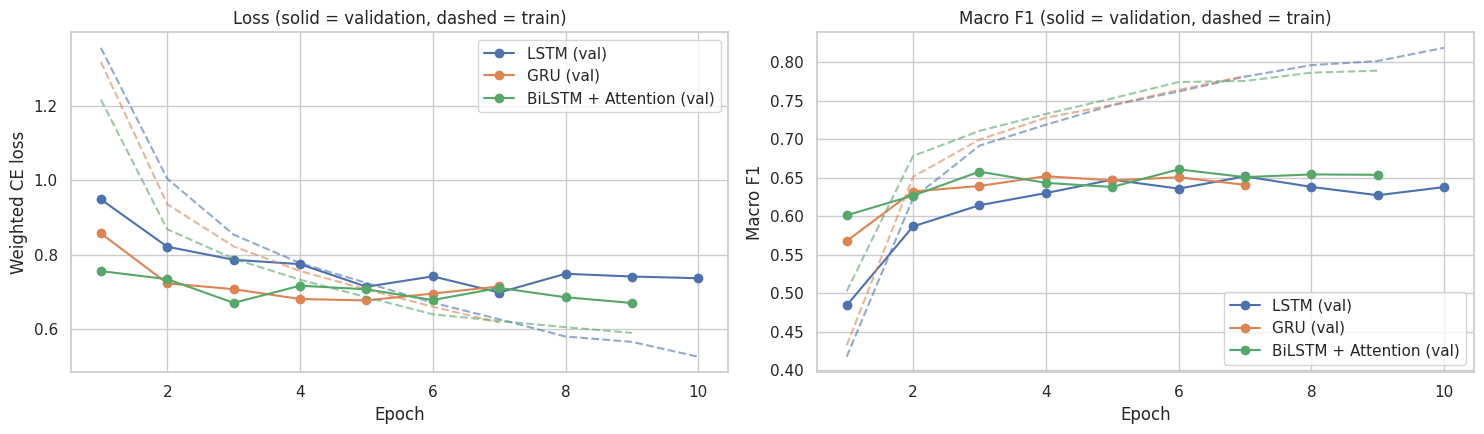

In [ ]:
def plot_histories(histories: Dict[str, Dict[str, List[float]]]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    for name, h in histories.items():
        epochs = range(1, len(h["val_loss"]) + 1)
        line, = axes[0].plot(epochs, h["val_loss"], marker="o", label=f"{name} (val)")
        axes[0].plot(epochs, h["train_loss"], linestyle="--", color=line.get_color(), alpha=0.6)
        line, = axes[1].plot(epochs, h["val_f1"], marker="o", label=f"{name} (val)")
        axes[1].plot(epochs, h["train_f1"], linestyle="--", color=line.get_color(), alpha=0.6)
    axes[0].set(title="Loss (solid = validation, dashed = train)", xlabel="Epoch", ylabel="Weighted CE loss")
    axes[1].set(title="Macro F1 (solid = validation, dashed = train)", xlabel="Epoch", ylabel="Macro F1")
    for ax in axes:
        ax.legend()
    plt.tight_layout()
    plt.show()


plot_histories(histories)

## 9. Evaluation of the Custom Models

Metrics required by the project: **accuracy, macro F1, per-class precision/recall, and confusion matrix**. All numbers below are computed on the held-out **test** split.

### 9.1 Evaluation helpers

In [ ]:
metrics_store: Dict[str, Dict[str, float]] = {}
per_class_store: Dict[str, pd.DataFrame] = {}


def evaluate_predictions(name: str, y_true: np.ndarray, y_pred: np.ndarray, plot: bool = True) -> None:
    """Compute, store, print and plot all required metrics for one model."""
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    per_class_store[name] = pd.DataFrame(
        {"precision": precision, "recall": recall, "f1": f1, "support": support}, index=TARGET_EMOTIONS)

    metrics_store[name] = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
        "macro_precision": float(np.mean(precision)),
        "macro_recall": float(np.mean(recall)),
    }

    print(f"===== {name} =====")
    print(f"Accuracy: {metrics_store[name]['accuracy']:.4f} | Macro F1: {metrics_store[name]['macro_f1']:.4f}")
    print(classification_report(y_true, y_pred, target_names=TARGET_EMOTIONS, digits=3, zero_division=0))

    if plot:
        cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
        cm_norm = cm / cm.sum(axis=1, keepdims=True)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=TARGET_EMOTIONS,
                    yticklabels=TARGET_EMOTIONS, ax=axes[0], cbar=False)
        axes[0].set(title=f"{name} - confusion matrix (counts)", xlabel="Predicted", ylabel="True")
        sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=TARGET_EMOTIONS,
                    yticklabels=TARGET_EMOTIONS, ax=axes[1], cbar=False, vmin=0, vmax=1)
        axes[1].set(title=f"{name} - confusion matrix (row-normalized = recall)", xlabel="Predicted", ylabel="True")
        plt.tight_layout()
        plt.show()

### 9.2 Evaluate LSTM, GRU and BiLSTM + Attention on the test set

===== LSTM =====
Accuracy: 0.7429 | Macro F1: 0.6364
              precision    recall  f1-score   support

         joy      0.900     0.807     0.851      1937
     sadness      0.584     0.617     0.600       298
       anger      0.626     0.629     0.627       609
        fear      0.543     0.671     0.600        85
    surprise      0.620     0.732     0.671       533
     disgust      0.362     0.662     0.468        77

    accuracy                          0.743      3539
   macro avg      0.606     0.686     0.636      3539
weighted avg      0.764     0.743     0.750      3539



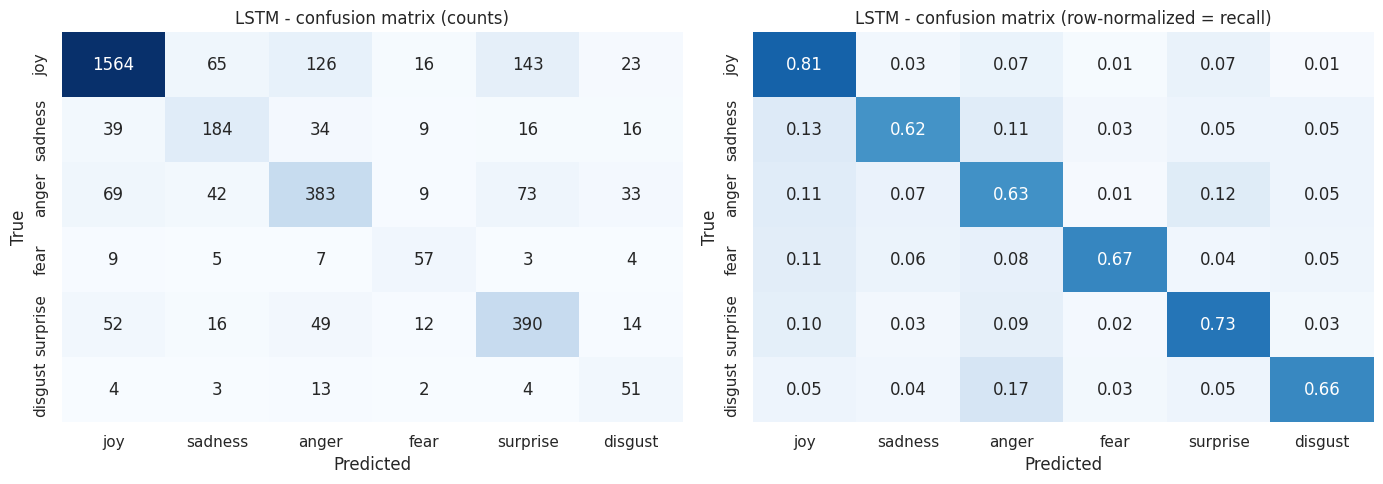

===== GRU =====
Accuracy: 0.7465 | Macro F1: 0.6453
              precision    recall  f1-score   support

         joy      0.881     0.826     0.852      1937
     sadness      0.560     0.624     0.590       298
       anger      0.642     0.598     0.619       609
        fear      0.540     0.718     0.616        85
    surprise      0.636     0.719     0.675       533
     disgust      0.444     0.623     0.519        77

    accuracy                          0.747      3539
   macro avg      0.617     0.685     0.645      3539
weighted avg      0.758     0.747     0.751      3539



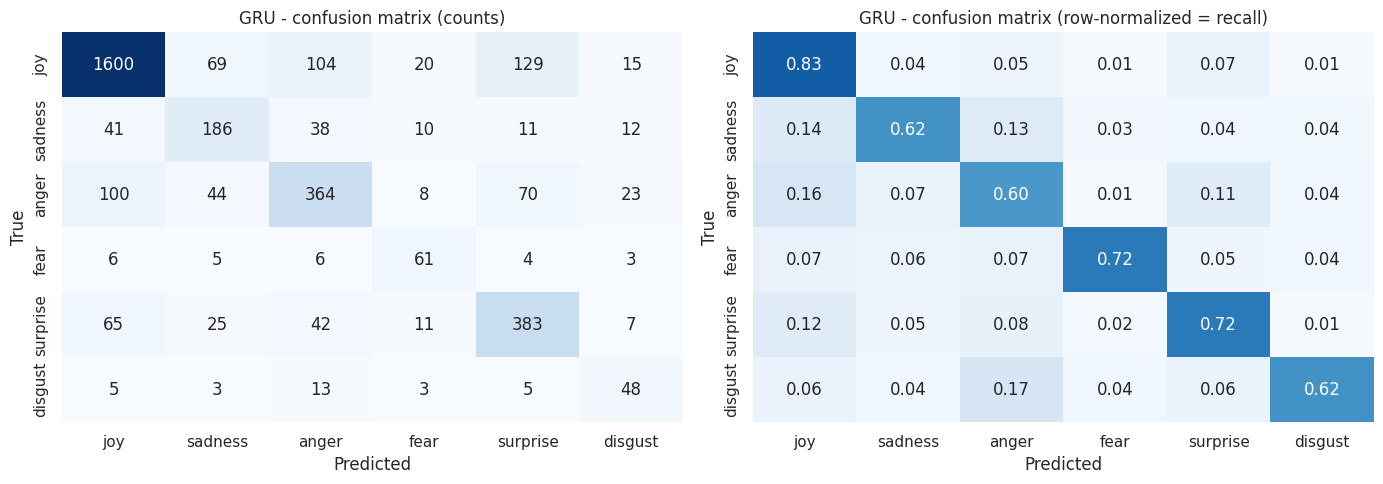

===== BiLSTM + Attention =====
Accuracy: 0.7578 | Macro F1: 0.6622
              precision    recall  f1-score   support

         joy      0.915     0.808     0.858      1937
     sadness      0.566     0.664     0.611       298
       anger      0.616     0.704     0.657       609
        fear      0.576     0.671     0.620        85
    surprise      0.656     0.724     0.689       533
     disgust      0.489     0.597     0.538        77

    accuracy                          0.758      3539
   macro avg      0.636     0.695     0.662      3539
weighted avg      0.778     0.758     0.765      3539



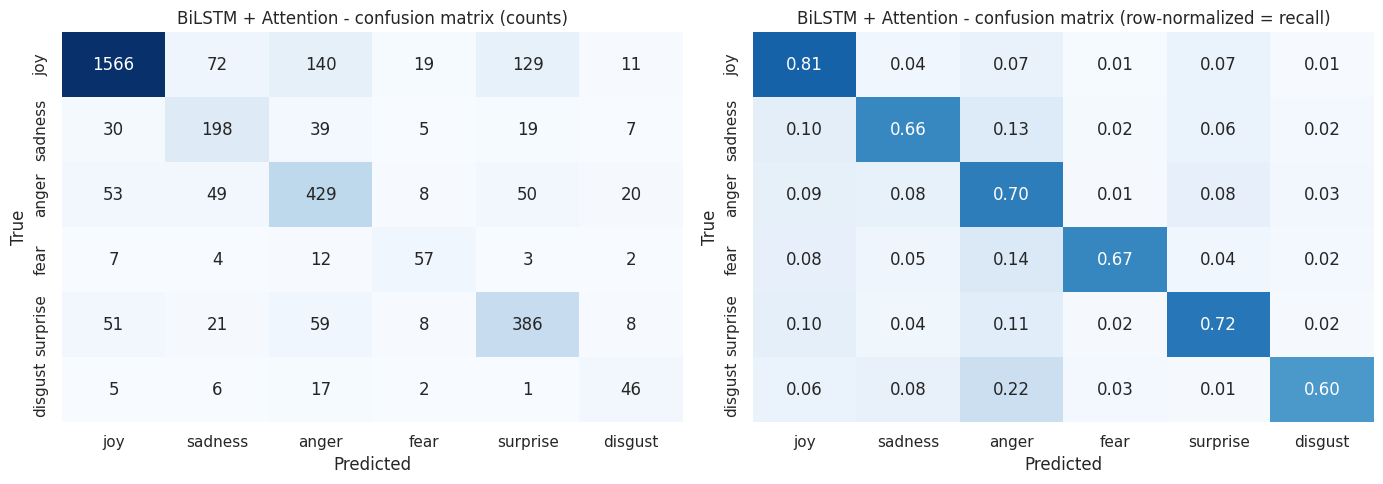

In [ ]:
for name, model in trained_models.items():
    y_true, y_pred, _ = predict(model, loaders["test"], device)
    evaluate_predictions(name, y_true, y_pred)

## 10. Attention Visualization

Attention weights show **which words the BiLSTM focuses on** when it makes a prediction. Higher weight (darker color) means the token contributed more to the context vector.

### 10.1 Explanation helpers

In [ ]:
@torch.no_grad()
def explain(text: str, model: BiLSTMAttention = None):
    """Return (tokens, attention_weights, class_probabilities) for one sentence."""
    model = model or trained_models["BiLSTM + Attention"]
    model.eval()
    tokens = tokenize(text)[:MAX_LEN]
    if not tokens:
        raise ValueError("The text has no usable tokens after cleaning.")
    ids, length = vocab.encode(tokens, MAX_LEN)
    ids_t = torch.tensor([ids], device=device)
    len_t = torch.tensor([length], device=device)
    logits, weights = model.attend(ids_t, len_t)
    probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    return tokens, weights[0, :length].cpu().numpy(), probs


def plot_attention(texts: List[str]) -> None:
    """Draw one attention heatmap row per sentence."""
    fig, axes = plt.subplots(len(texts), 1, figsize=(13, 1.9 * len(texts)), squeeze=False)
    for ax, text in zip(axes[:, 0], texts):
        tokens, weights, probs = explain(text)
        sns.heatmap(weights[None, :], annot=np.array([[f"{w:.2f}" for w in weights]]), fmt="",
                    cmap="Reds", cbar=False, xticklabels=tokens, yticklabels=[""], ax=ax,
                    vmin=0, vmax=max(weights.max(), 1e-6), linewidths=0.5, linecolor="white")
        pred = int(probs.argmax())
        ax.set_title(f"Predicted: {ID2EMOTION[pred]} ({probs[pred]:.1%})", loc="left", fontsize=11)
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()

### 10.2 Heatmaps for example sentences

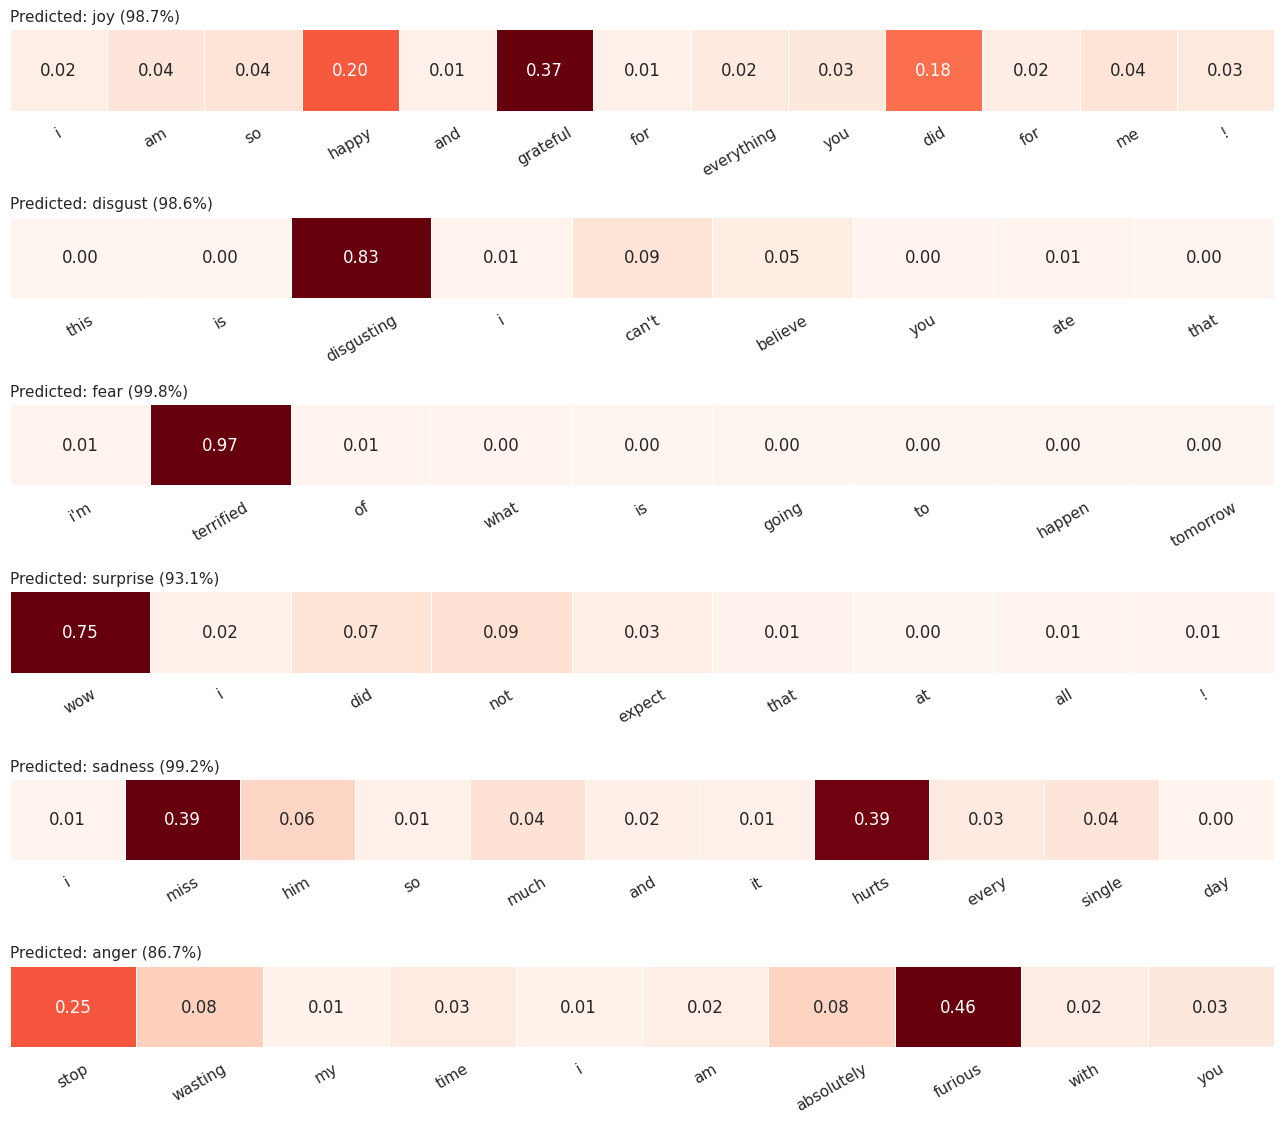

In [ ]:
example_sentences = [
    "I am so happy and grateful for everything you did for me!",
    "This is disgusting, I can't believe you ate that.",
    "I'm terrified of what is going to happen tomorrow.",
    "Wow, I did not expect that at all!",
    "I miss him so much and it hurts every single day.",
    "Stop wasting my time, I am absolutely furious with you.",
]
plot_attention(example_sentences)

### 10.3 Try your own text

Type any sentence to see the prediction and its attention heatmap. Enter `q` to stop.

Enter a sentence (or 'q' to quit): I am so happy today!


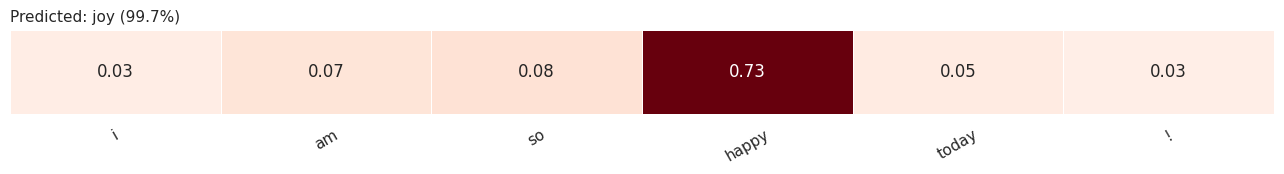

Enter a sentence (or 'q' to quit): 


In [ ]:
while True:
    user_text = input("Enter a sentence (or 'q' to quit): ").strip()
    if user_text.lower() in {"q", "quit", ""}:
        break
    try:
        plot_attention([user_text])
    except ValueError as err:
        print(err)

## 11. Fine-tuning a Transformer with HuggingFace

We fine-tune `roberta-large` (355M params) with the HuggingFace `Trainer` API, on the exact same train/val/test split as above. To fit a free Colab GPU we keep the per-step batch small (`transformer_batch_size = 8`) and use gradient accumulation (`transformer_grad_accum = 4`) to still get an effective batch of 32, plus a lower learning rate (`1e-5`) since big pretrained models are easier to mess up with a high LR. It'll take longer per epoch than a base model, but `EarlyStoppingCallback` stops it once val macro F1 plateaus. Swap `cfg.transformer_name` for `"roberta-base"` or `"distilbert-base-uncased"` if you want something faster.

### 11.1 Tokenize the data for the transformer

The tokenizer matching `cfg.transformer_name` is loaded automatically. Padding is applied dynamically per batch by the data collator.

In [ ]:
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
)
from transformers import set_seed as hf_set_seed

tokenizer = AutoTokenizer.from_pretrained(cfg.transformer_name)


def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=cfg.transformer_max_len)


hf_datasets = DatasetDict({
    split: Dataset.from_pandas(frames[split][["text", "label"]].reset_index(drop=True))
    for split in ["train", "validation", "test"]
}).map(tokenize_batch, batched=True, remove_columns=["text"])

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(hf_datasets)

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/32665 [00:00<?, ? examples/s]

Map:   0%|          | 0/3527 [00:00<?, ? examples/s]

Map:   0%|          | 0/3539 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 32665
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 3527
    })
    test: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 3539
    })
})


### 11.2 Model, weighted-loss Trainer and metrics

We subclass `Trainer` only to plug in the **same class-weighted loss** used for the recurrent models.

In [ ]:
class WeightedLossTrainer(Trainer):
    """HuggingFace Trainer with a class-weighted cross-entropy loss."""

    def __init__(self, *args, class_weights: torch.Tensor = None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weight = self.class_weights.to(outputs.logits.device)
        loss = F.cross_entropy(outputs.logits, labels, weight=weight)
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "macro_f1": f1_score(labels, preds, average="macro")}


hf_set_seed(cfg.seed)
transformer_model = AutoModelForSequenceClassification.from_pretrained(
    cfg.transformer_name, num_labels=NUM_CLASSES, id2label=ID2EMOTION, label2id=EMOTION2ID)

# Display name used everywhere below, so it always matches cfg.transformer_name instead of being hardcoded.
TRANSFORMER_LABEL = f"{cfg.transformer_name} (fine-tuned)"

# warmup_steps instead of warmup_ratio - works on older transformers versions too
optimizer_steps_per_epoch = -(-len(hf_datasets["train"]) // (cfg.transformer_batch_size * cfg.transformer_grad_accum))
warmup_steps = int(0.1 * optimizer_steps_per_epoch * cfg.transformer_epochs)

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "transformer_checkpoints"),
    num_train_epochs=cfg.transformer_epochs,
    learning_rate=cfg.transformer_lr,
    per_device_train_batch_size=cfg.transformer_batch_size,
    per_device_eval_batch_size=cfg.transformer_batch_size * 2,
    gradient_accumulation_steps=cfg.transformer_grad_accum,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    logging_steps=100,
    fp16=torch.cuda.is_available(),
    seed=cfg.seed,
    report_to="none",
)

trainer = WeightedLossTrainer(
    model=transformer_model,
    args=training_args,
    train_dataset=hf_datasets["train"],
    eval_dataset=hf_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    class_weights=class_weights,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=cfg.transformer_patience)],
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-large
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### 11.3 Fine-tune

In [ ]:
train_output = trainer.train()
print(f"Training time: {train_output.metrics['train_runtime']:.0f}s")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,2.917093,0.621646,0.811738,0.699882
2,2.334896,0.574507,0.823646,0.713972
3,1.851202,0.607009,0.817976,0.714594
4,1.459677,0.643928,0.822796,0.714792
5,1.055487,0.725259,0.812872,0.706668
6,0.966578,0.754295,0.814290,0.699213


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 3978s


### 11.4 Evaluate the fine-tuned transformer on the test set

===== roberta-large (fine-tuned) =====
Accuracy: 0.8127 | Macro F1: 0.7159
              precision    recall  f1-score   support

         joy      0.920     0.890     0.905      1937
     sadness      0.642     0.721     0.679       298
       anger      0.724     0.690     0.706       609
        fear      0.677     0.765     0.718        85
    surprise      0.718     0.765     0.741       533
     disgust      0.511     0.584     0.545        77

    accuracy                          0.813      3539
   macro avg      0.699     0.736     0.716      3539
weighted avg      0.818     0.813     0.815      3539



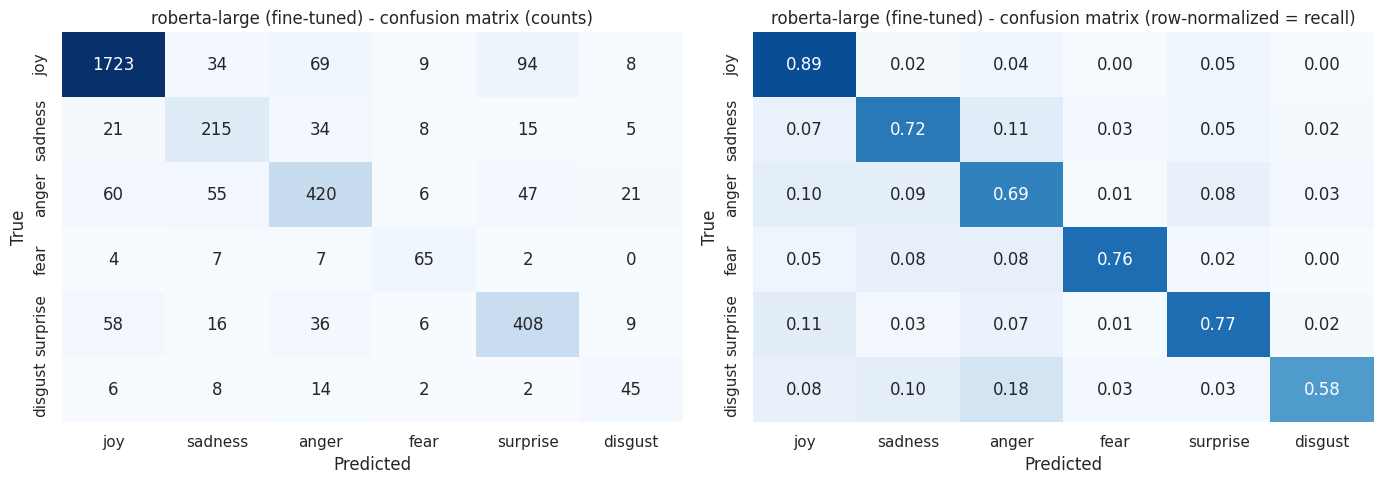

In [ ]:
test_output = trainer.predict(hf_datasets["test"])
distilbert_probs = torch.softmax(torch.tensor(test_output.predictions), dim=-1).numpy()
distilbert_pred = distilbert_probs.argmax(axis=1)
distilbert_true = test_output.label_ids

evaluate_predictions(TRANSFORMER_LABEL, distilbert_true, distilbert_pred)

## 12. Final Comparison

### 12.1 Metrics table and chart

,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
roberta-large (fine-tuned),0.8127,0.7159,0.8147,0.6988,0.7359
BiLSTM + Attention,0.7578,0.6622,0.7647,0.6364,0.6949
GRU,0.7465,0.6453,0.7505,0.6172,0.6846
LSTM,0.7429,0.6364,0.7502,0.6058,0.6864


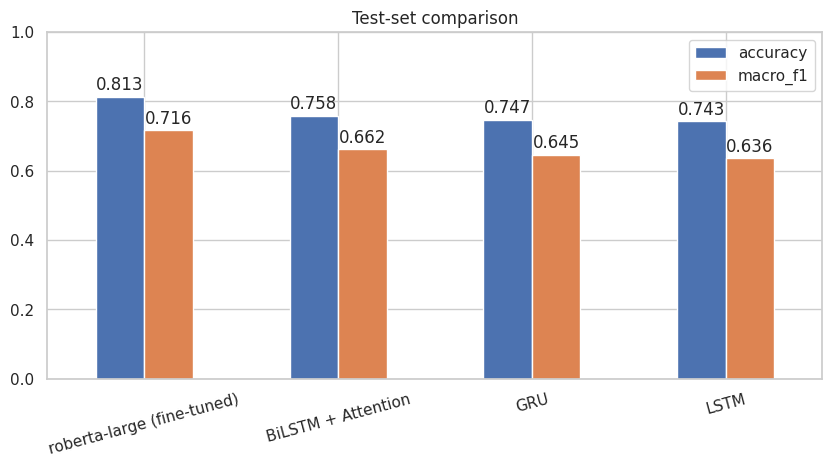

Best model by macro F1: roberta-large (fine-tuned)


In [ ]:
results_df = pd.DataFrame(metrics_store).T.sort_values("macro_f1", ascending=False)
display(results_df.style.format("{:.4f}").background_gradient(cmap="Greens", axis=0))

ax = results_df[["accuracy", "macro_f1"]].plot.bar(figsize=(10, 4.5), rot=15)
ax.set_title("Test-set comparison")
ax.set_ylim(0, 1)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2)
plt.show()

best_model_name = results_df.index[0]
print(f"Best model by macro F1: {best_model_name}")

### 12.2 Per-class precision, recall and F1 across models

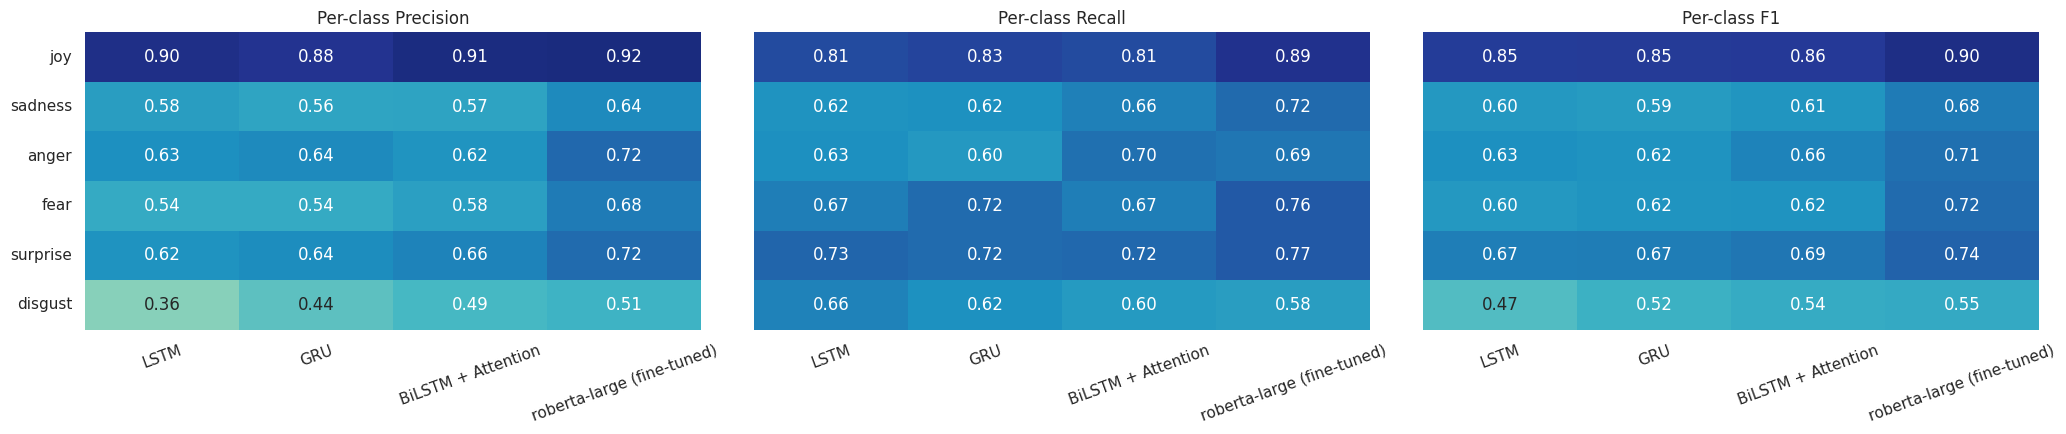

In [ ]:
per_class_f1 = pd.DataFrame({name: df["f1"] for name, df in per_class_store.items()})
per_class_precision = pd.DataFrame({name: df["precision"] for name, df in per_class_store.items()})
per_class_recall = pd.DataFrame({name: df["recall"] for name, df in per_class_store.items()})

fig, axes = plt.subplots(1, 3, figsize=(21, 4.5), sharey=True)
for ax, (title, table) in zip(axes, [("Precision", per_class_precision), ("Recall", per_class_recall), ("F1", per_class_f1)]):
    sns.heatmap(table, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"Per-class {title}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 12.3 Try all four models on your own text

Type a sentence and compare the predictions of every model side by side. Enter `q` to stop.

In [ ]:
@torch.no_grad()
def rnn_probs(model: nn.Module, text: str) -> np.ndarray:
    model.eval()
    tokens = tokenize(text)[:MAX_LEN]
    ids, length = vocab.encode(tokens if tokens else [vocab.UNK], MAX_LEN)
    logits = model(torch.tensor([ids], device=device), torch.tensor([length], device=device))
    return torch.softmax(logits, dim=-1)[0].cpu().numpy()


@torch.no_grad()
def distilbert_probs_for(text: str) -> np.ndarray:
    model = trainer.model.eval()
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=cfg.transformer_max_len).to(model.device)
    return torch.softmax(model(**enc).logits, dim=-1)[0].cpu().numpy()


def compare_on_text(text: str) -> pd.DataFrame:
    rows = {name: rnn_probs(model, text) for name, model in trained_models.items()}
    rows[TRANSFORMER_LABEL] = distilbert_probs_for(text)
    table = pd.DataFrame(rows, index=TARGET_EMOTIONS).T
    table["prediction"] = table[TARGET_EMOTIONS].idxmax(axis=1)
    return table


while True:
    user_text = input("Enter a sentence (or 'q' to quit): ").strip()
    if user_text.lower() in {"q", "quit", ""}:
        break
    display(compare_on_text(user_text).style.format({e: "{:.2f}" for e in TARGET_EMOTIONS}))

Enter a sentence (or 'q' to quit):  can't believe you did this, I am furious


,joy,sadness,anger,fear,surprise,disgust,prediction
LSTM,0.03,0.06,0.13,0.00,0.77,0.00,surprise
GRU,0.10,0.14,0.20,0.01,0.53,0.01,surprise
BiLSTM + Attention,0.09,0.11,0.25,0.01,0.54,0.00,surprise
roberta-large (fine-tuned),0.00,0.00,0.91,0.00,0.08,0.00,anger


Enter a sentence (or 'q' to quit): 


## 13. Saving Artifacts

We save everything needed to **reload the models for deployment** later: model weights, vocabulary, embedding/model hyperparameters, label maps, and the fine-tuned transformer with its tokenizer.

### 13.1 Save models, vocabulary and metadata

In [ ]:
def slugify(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


for name, model in trained_models.items():
    torch.save(model.state_dict(), OUTPUT_DIR / f"{slugify(name)}.pt")

with open(OUTPUT_DIR / "vocab.json", "w", encoding="utf-8") as f:
    json.dump(vocab.itos, f)

metadata = {
    "config": asdict(cfg),
    "max_len": MAX_LEN,
    "vocab_size": len(vocab),
    "embed_dim": int(embedding_matrix.shape[1]),
    "labels": TARGET_EMOTIONS,
    "go_to_ekman_mapping": EKMAN_MAPPING,
    "test_metrics": metrics_store,
    "best_model": best_model_name,
}
with open(OUTPUT_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

trainer.save_model(str(OUTPUT_DIR / "finetuned_transformer"))
tokenizer.save_pretrained(str(OUTPUT_DIR / "finetuned_transformer"))

print("Saved files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(" -", path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved files:
 - artifacts/bilstm_attention.pt
 - artifacts/finetuned_transformer
 - artifacts/gru.pt
 - artifacts/lstm.pt
 - artifacts/metadata.json
 - artifacts/transformer_checkpoints
 - artifacts/vocab.json


## 14. Conclusions and Next Steps

Four models trained and compared on the same GoEmotions-based split: LSTM, GRU, BiLSTM+Attention, and `roberta-large` fine-tuned with HuggingFace's `Trainer`. `roberta-large` came out on top on every metric, but the custom RNNs aren't far off considering they're a fraction of the size.

A few things worth calling out for the report: only single-emotion examples are kept in val/test (ambiguous ones get dropped there, resolved-by-priority in train only), vocab and class weights are built from train only so nothing leaks, and macro F1 is the metric that actually matters here since the classes are this imbalanced. `disgust` and `fear` got a boost from mixing in ISEAR data, and the sqrt-dampened class balancing (`sampling_alpha`) fixed the precision collapse that showed up with full inverse-frequency weighting.

Next step is wrapping this into a **Streamlit or Gradio** app using the saved `artifacts/` — type in a sentence, get back the predicted emotion plus a confidence bar chart across the 6 classes.